## 1. Import Required Libraries

In [21]:
import sys
from pathlib import Path

# Add project root to path
sys.path.insert(0, str(Path.cwd()))

from src.models.product_customer_forecast import ProductCustomerForecaster, ForecastConfig
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("✓ Imports successful")

✓ Imports successful


## 2. Configure Forecast Parameters

Set your parameters here - equivalent to CLI arguments.

In [22]:
# ============================================================================
# CONFIGURATION PARAMETERS
# ============================================================================

# Data file path (Excel or CSV)
DATA_FILE = 'data/dummy_product_customer_data.xlsx'  # Change this to your data file

# Forecast settings
FORECAST_YEARS = 3              # Number of years to forecast
MIN_OBSERVATIONS = 3            # Minimum historical data points required

# Visualization
ENABLE_VISUALIZATIONS = False   # Generate charts (saved to outputs folder)

# Data aggregation
AGGREGATION_MODE = 'yearly'     # 'yearly' or 'monthly'

# Parallel processing
PARALLEL_PROCESSING = True      # Enable parallel processing for speed
NUM_WORKERS = 4                 # Number of CPU cores to use

# Output options
ROUND_FORECASTS = True          # Round forecasts to integers

# Filters (optional - set to None to process all)
FILTER_PRODUCT = None           # Filter by specific product (e.g., 'Product_1')
FILTER_CUSTOMER = None          # Filter by specific customer (e.g., 'CUST_001')

print("✓ Configuration set")
print(f"  Data file: {DATA_FILE}")
print(f"  Forecast years: {FORECAST_YEARS}")
print(f"  Parallel processing: {PARALLEL_PROCESSING}")
print(f"  Visualizations: {ENABLE_VISUALIZATIONS}")

✓ Configuration set
  Data file: data/dummy_product_customer_data.xlsx
  Forecast years: 3
  Parallel processing: True
  Visualizations: False


## 3. Create Forecast Configuration

In [23]:
# Create configuration object
config = ForecastConfig(
    data_path=Path(DATA_FILE),
    forecast_years=FORECAST_YEARS,
    min_observations=MIN_OBSERVATIONS,
    visualize=ENABLE_VISUALIZATIONS,
    aggregation_mode=AGGREGATION_MODE,
    parallel_processing=PARALLEL_PROCESSING,
    num_workers=NUM_WORKERS,
    round_forecasts=ROUND_FORECASTS,
    filter_product=FILTER_PRODUCT,
    filter_customer=FILTER_CUSTOMER
)

print("✓ Configuration created successfully")

✓ Configuration created successfully


## 4. Run Forecaster

This will:
- Load your data
- Group by products
- Train ARIMA models
- Generate forecasts
- Save models and metadata

In [24]:
# Create forecaster instance
forecaster = ProductCustomerForecaster(config)

# Run the forecasting process
forecaster.run()

print("\n✓ Forecasting complete!")

✓ Output directories ready: /home/vineet/Desktop/projects/arima/outputs/product_customer_forecasts
PRODUCT FORECASTING SYSTEM (Grouped by Product)

Loading data from: data/dummy_product_customer_data.xlsx
✓ Loaded 10000 records
  Columns: Year, Month, Product Category, Product, CustomerID, Quantity

Preparing time series data...
  Aggregation mode: yearly
  Grouping by: Product (aggregating all CustomerIDs per product)
✓ Created 50 Product groups
  Total unique CustomerIDs across products: 4304
  (Filtered out products with < 3 observations)

Training ARIMA models...
Processing 50 products...
Aggregation mode: yearly
Parallel processing: Enabled

Using 4 workers

✓ Loaded 10000 records
  Columns: Year, Month, Product Category, Product, CustomerID, Quantity

Preparing time series data...
  Aggregation mode: yearly
  Grouping by: Product (aggregating all CustomerIDs per product)
✓ Created 50 Product groups
  Total unique CustomerIDs across products: 4304
  (Filtered out products with < 3

Training models (parallel): 100%|██████████| 50/50 [00:44<00:00,  1.13it/s]


FORECAST SUMMARY
Total Products: 50
Total Customers (aggregated): 4304
Successful: 50
Failed: 0
Average MAPE: nan%

Forecast Horizon: 3 years
Results saved to: /home/vineet/Desktop/projects/arima/outputs/product_customer_forecasts

✓ ANALYSIS COMPLETE!

✓ Forecasting complete!


## 5. Get Results as DataFrame

Retrieve forecast results - no Excel files needed!

In [25]:
# Get all forecasts as a DataFrame
results_df = forecaster.get_results_dataframe()

print(f"Total forecast records: {len(results_df)}")
print(f"Number of products: {results_df['Product'].nunique()}")
print(f"\nColumns: {list(results_df.columns)}")

# Display first few rows
results_df.head(10)

Total forecast records: 150
Number of products: 50

Columns: ['Product', 'Num_Customers', 'Date', 'Forecast']


,Product,Num_Customers,Date,Forecast
0,Product_1,90,2025-01-01,842
1,Product_1,90,2026-01-01,842
2,Product_1,90,2027-01-01,842
3,Product_10,83,2025-01-01,826
4,Product_10,83,2026-01-01,826
5,Product_10,83,2027-01-01,826
6,Product_11,89,2025-01-01,863
7,Product_11,89,2026-01-01,863
8,Product_11,89,2027-01-01,863
9,Product_12,86,2025-01-01,759


## 6. Analyze Results

In [16]:
# Summary statistics
print("Forecast Summary by Product:")
print("=" * 60)

summary = results_df.groupby('Product').agg({
    'Forecast': ['sum', 'mean', 'min', 'max'],
    'Num_Customers': 'first'
}).round(2)

summary.columns = ['Total_Forecast', 'Avg_Forecast', 'Min_Forecast', 'Max_Forecast', 'Num_Customers']
summary = summary.sort_values('Total_Forecast', ascending=False)

summary

Forecast Summary by Product:


,Total_Forecast,Avg_Forecast,Min_Forecast,Max_Forecast,Num_Customers
Product,,,,,
Product_33,2670,890.00,890,890,85
Product_27,2661,887.00,887,887,88
Product_40,2628,876.00,876,876,88
Product_11,2589,863.00,863,863,89
Product_44,2584,861.33,712,981,86
Product_3,2580,860.00,860,860,95
Product_49,2580,860.00,860,860,86
Product_17,2577,859.00,859,859,87
Product_36,2538,846.00,846,846,86


## 7. View Specific Product Forecast

In [19]:
# Select a product to view detailed forecast
if 'Product' in results_df.columns and len(results_df) > 0:
    product_name = results_df['Product'].iloc[0]  # First product
    
    print(f"Detailed Forecast for: {product_name}")
    print("=" * 60)
    
    product_forecast = results_df[results_df['Product'] == product_name]
    display(product_forecast)
else:
    print("❌ Please run cell 5 first to generate results_df")

Detailed Forecast for: Product_1


,Product,Num_Customers,Date,Forecast
0,Product_1,90,2025-01-01,842
1,Product_1,90,2026-01-01,842
2,Product_1,90,2027-01-01,842


## 8. View Individual Model Results

Access detailed model information including ARIMA parameters and accuracy metrics.

In [17]:
# Display model details for first few products
print("Model Details:")
print("=" * 60)

for i, result in enumerate(forecaster.results[:5], 1):  # First 5 results
    if result.success:
        print(f"\n{i}. Product: {result.product}")
        print(f"   Customers: {result.num_customers}")
        print(f"   ARIMA Order: {result.order}")
        print(f"   Seasonal Order: {result.seasonal_order}")
        if result.rmse:
            print(f"   RMSE: {result.rmse:.2f}")
        if result.mae:
            print(f"   MAE: {result.mae:.2f}")
        if result.mape:
            print(f"   MAPE: {result.mape:.2f}%")
    else:
        print(f"\n{i}. Product: {result.product} - FAILED")
        print(f"   Error: {result.error_message}")

Model Details:

1. Product: Product_1
   Customers: 90
   ARIMA Order: (0, 0, 0)
   Seasonal Order: (0, 0, 0, 0)
   RMSE: 161.80
   MAE: 161.80
   MAPE: nan%

2. Product: Product_10
   Customers: 83
   ARIMA Order: (0, 0, 0)
   Seasonal Order: (0, 0, 0, 0)
   RMSE: 24.20
   MAE: 24.20
   MAPE: nan%

3. Product: Product_11
   Customers: 89
   ARIMA Order: (0, 0, 0)
   Seasonal Order: (0, 0, 0, 0)
   RMSE: 101.60
   MAE: 101.60
   MAPE: nan%

4. Product: Product_12
   Customers: 86
   ARIMA Order: (0, 0, 0)
   Seasonal Order: (0, 0, 0, 0)
   RMSE: 209.60
   MAE: 209.60
   MAPE: nan%

5. Product: Product_13
   Customers: 89
   ARIMA Order: (1, 0, 1)
   Seasonal Order: (0, 0, 0, 0)
   RMSE: 530.79
   MAE: 530.79
   MAPE: nan%


## 10. Quick Visualization (Optional)

Create a simple chart to visualize forecasts.

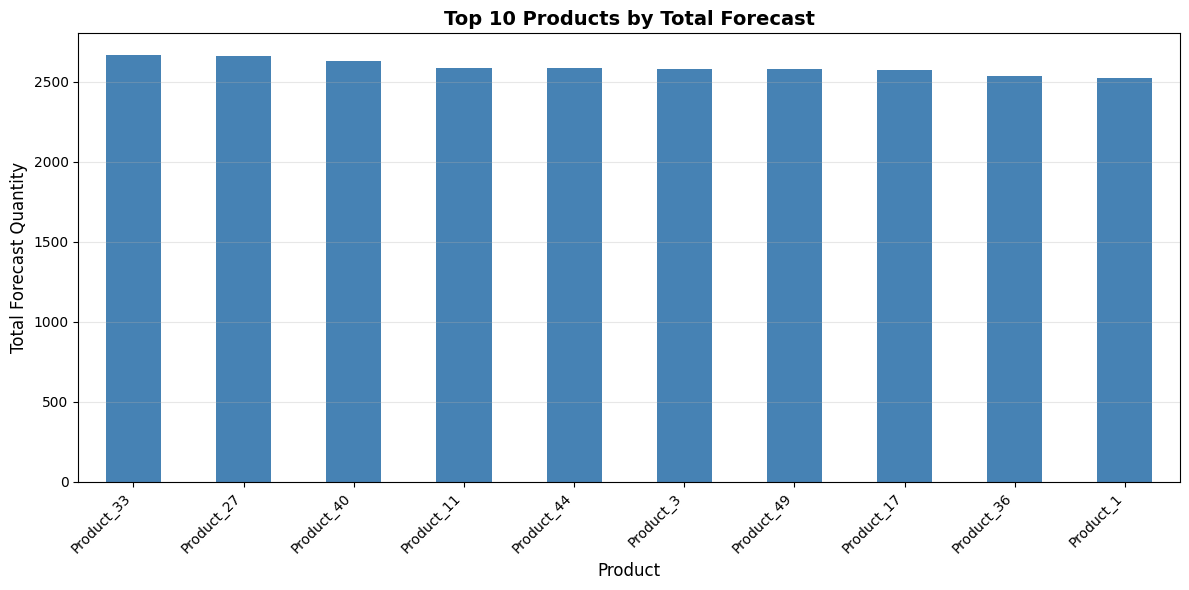


Top 10 Products:
Product
Product_33    2670
Product_27    2661
Product_40    2628
Product_11    2589
Product_44    2584
Product_3     2580
Product_49    2580
Product_17    2577
Product_36    2538
Product_1     2526
Name: Forecast, dtype: int64


In [26]:
import matplotlib.pyplot as plt

# Check if results_df has the right columns
if 'Product' in results_df.columns and 'Forecast' in results_df.columns and len(results_df) > 0:
    # Plot total forecast by product (top 10)
    top_products = results_df.groupby('Product')['Forecast'].sum().sort_values(ascending=False).head(10)
    
    plt.figure(figsize=(12, 6))
    top_products.plot(kind='bar', color='steelblue')
    plt.title('Top 10 Products by Total Forecast', fontsize=14, fontweight='bold')
    plt.xlabel('Product', fontsize=12)
    plt.ylabel('Total Forecast Quantity', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    print(f"\nTop 10 Products:")
    print(top_products)
else:
    print("❌ Please run cell 5 first to generate results_df")

## 📊 Output Locations

Your results are saved in:
- **Models**: `outputs/product_customer_forecasts/models/` - Pickled ARIMA models
- **Metadata**: `outputs/product_customer_forecasts/metadata/` - JSON files with model details
- **Visualizations**: `outputs/product_customer_forecasts/visualizations/` - PNG charts (if enabled)

## 🔄 Re-run with Different Parameters

To forecast with different settings:
1. Go back to **Cell 2** (Configuration Parameters)
2. Modify the parameters
3. Run cells 2-4 again